# 05 · Comparison: Heuristics vs. Machine Learning vs. Deep Learning

Each of the notebooks 02–04 saved its results in `results/`. Here we put them side by side and answer the central question of Chapter 1: **which approach should you choose, and when?**

We compare four dimensions:
1. **Quality**: accuracy and F1 on the same 5,000 IMDB test reviews.
2. **Cost**: training and prediction time.
3. **Data needs**: how many labelled examples each approach requires.
4. **Behaviour**: which reviews each approach gets right or wrong.

> Run notebooks 02, 03 and 04 first. This notebook only reads their saved results.

In [1]:
# --- Make the project's `src` folder importable -----------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import RESULTS_DIR, PREDICTIONS_DIR, FIGURES_DIR

# Nicer display names for the plots and tables
PRETTY = {
    "heuristic_lexicon": "Own lexicon + rules",
    "heuristic_vader": "VADER (rule-based)",
    "ml_naive_bayes": "TF-IDF + Naive Bayes",
    "ml_logistic_regression": "TF-IDF + Logistic Regression",
    "dl_distilbert_finetuned": "DistilBERT fine-tuned on IMDB",
    "dl_sst2_pretrained": "Ready-made SST-2 model (no IMDB training)",
}
# Colour per family, so the three approaches are easy to tell apart in plots
FAMILY_COLORS = {"heuristic": "#8172B3", "machine_learning": "#4C72B0", "deep_learning": "#DD8452"}
FAMILY_ORDER = {"heuristic": 0, "machine_learning": 1, "deep_learning": 2}

## 1. Load all results

In [3]:
records = []
for path in sorted(RESULTS_DIR.glob("*.json")):
    if path.stem.startswith("learning_curve"):      # this file has a different format
        continue
    with open(path, encoding="utf-8") as f:
        records.append(json.load(f))

results = pd.DataFrame(records)
results["name"] = results["approach"].map(PRETTY).fillna(results["approach"])

# Sort: first by family (heuristic -> ML -> DL), then by accuracy within each family
results["family_rank"] = results["family"].map(FAMILY_ORDER)
results = results.sort_values(["family_rank", "accuracy"]).reset_index(drop=True)

results[["name", "family", "accuracy", "f1_macro", "n_train_examples",
         "train_seconds", "predict_seconds"]]

,name,family,accuracy,f1_macro,n_train_examples,train_seconds,predict_seconds
0,VADER (rule-based),heuristic,0.7106,0.7077,0,0.000,5.294
1,Own lexicon + rules,heuristic,0.7332,0.7210,0,0.000,0.361
2,TF-IDF + Naive Bayes,machine_learning,0.8618,0.8616,22500,0.094,2.296
3,TF-IDF + Logistic Regression,machine_learning,0.9038,0.9038,22500,1.673,2.513
4,Ready-made SST-2 model (no IMDB training),deep_learning,0.8802,0.8801,0,0.000,515.389
5,DistilBERT fine-tuned on IMDB,deep_learning,0.8972,0.8972,4000,2670.628,335.860


## 2. Quality: accuracy

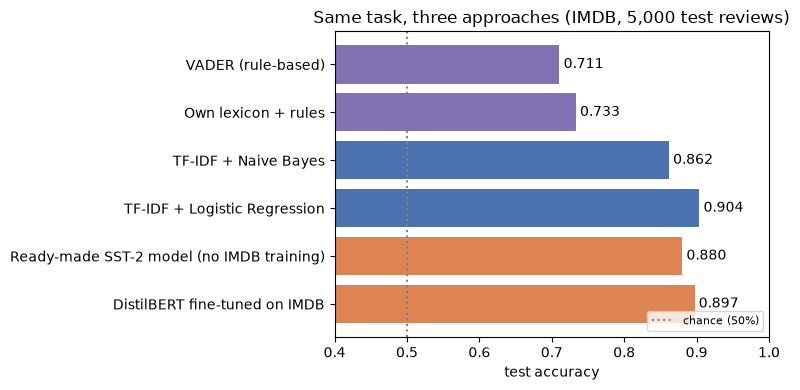

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [FAMILY_COLORS[f] for f in results["family"]]
bars = ax.barh(results["name"], results["accuracy"], color=colors)
ax.bar_label(bars, fmt="%.3f", padding=3)           # write the value next to each bar
ax.axvline(0.5, color="gray", linestyle=":", label="chance (50%)")

ax.set_xlim(0.4, 1.0)
ax.set_xlabel("test accuracy")
ax.set_title("Same task, three approaches (IMDB, 5,000 test reviews)")
ax.invert_yaxis()                                   # first row at the top
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_comparison.png", dpi=120)
plt.show()

### A fair comparison: same amount of training data

On a CPU, notebook 04 fine-tunes DistilBERT on a sample of **4,000** reviews, while the TF-IDF models use all 22,500. To compare the two *methods* fairly, we also look at Logistic Regression trained on the same number of reviews (taken from the learning curve in notebook 03).

In [5]:
with open(RESULTS_DIR / "learning_curve_ml.json", encoding="utf-8") as f:
    curve = pd.DataFrame(json.load(f))

dl = results[results["approach"] == "dl_distilbert_finetuned"]
if len(dl):
    n_dl = int(dl["n_train_examples"].iloc[0])
    same_n = curve[curve["n_train"] == n_dl]
    print(f"DistilBERT fine-tuned on {n_dl:,} reviews  : accuracy {dl['accuracy'].iloc[0]:.4f}")
    if len(same_n):
        print(f"Logistic Regression on {n_dl:,} reviews    : accuracy {same_n['test_accuracy'].iloc[0]:.4f}")
    print(f"Logistic Regression on all {curve['n_train'].max():,} reviews: "
          f"accuracy {curve['test_accuracy'].iloc[-1]:.4f}")
else:
    print("Run notebook 04 first.")

DistilBERT fine-tuned on 4,000 reviews  : accuracy 0.8972
Logistic Regression on 4,000 reviews    : accuracy 0.8756
Logistic Regression on all 22,500 reviews: accuracy 0.9038


## 3. Cost: training and prediction time

Accuracy is not the only thing that matters in a real product. Prediction speed decides how many requests one server can handle, and training time decides how quickly you can iterate.

,name,train_minutes,seconds_per_1000_reviews
0,VADER (rule-based),0.00,1.059
1,Own lexicon + rules,0.00,0.072
2,TF-IDF + Naive Bayes,0.00,0.459
3,TF-IDF + Logistic Regression,0.03,0.503
4,Ready-made SST-2 model (no IMDB training),0.00,103.078
5,DistilBERT fine-tuned on IMDB,44.51,67.172


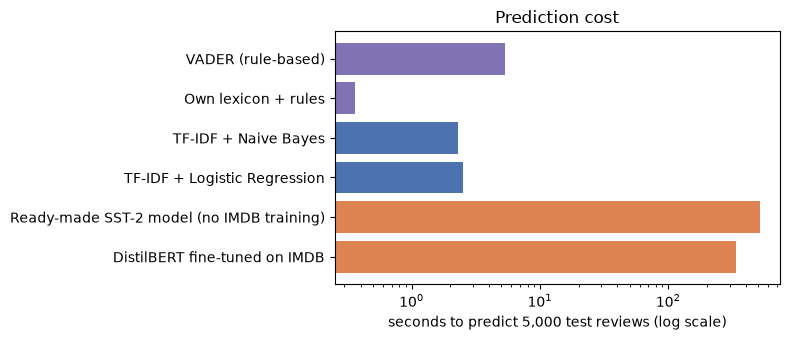

In [6]:
cost = results[["name", "family", "train_seconds", "predict_seconds"]].copy()

# Number of test reviews, read from one of the prediction files
n_test = len(pd.read_csv(next(PREDICTIONS_DIR.glob("*.csv"))))

# Time to predict 1,000 reviews, so the numbers are easy to compare
cost["seconds_per_1000_reviews"] = (cost["predict_seconds"] / n_test * 1000).round(3)
cost["train_minutes"] = (cost["train_seconds"] / 60).round(2)
display(cost[["name", "train_minutes", "seconds_per_1000_reviews"]])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cost["name"], cost["predict_seconds"].clip(lower=1e-3),
        color=[FAMILY_COLORS[f] for f in cost["family"]])
ax.set_xscale("log")                                # times differ by orders of magnitude
ax.set_xlabel(f"seconds to predict {n_test:,} test reviews (log scale)")
ax.set_title("Prediction cost")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "prediction_cost.png", dpi=120)
plt.show()

Note the **log scale**: the deep-learning models are typically orders of magnitude slower than the linear models, especially on a CPU.

## 4. Data needs: the learning curve

Approaches that use **no IMDB labels** (the heuristics and the ready-made SST-2 model) appear as horizontal lines. Classic ML improves with more data. Our fine-tuned transformer is shown as a star at the number of reviews it was trained on.

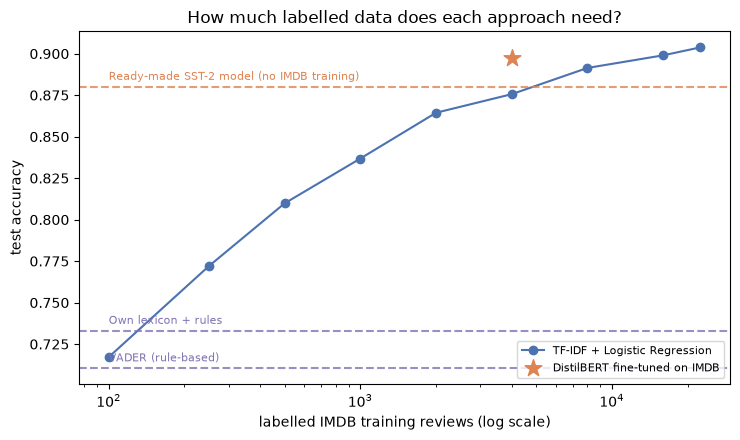

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogx(curve["n_train"], curve["test_accuracy"], marker="o",
            color=FAMILY_COLORS["machine_learning"], label="TF-IDF + Logistic Regression")

# Horizontal lines for everything that needs 0 labelled IMDB examples
for _, row in results[results["n_train_examples"] == 0].iterrows():
    color = FAMILY_COLORS[row["family"]]
    ax.axhline(row["accuracy"], color=color, linestyle="--", alpha=0.8)
    ax.text(curve["n_train"].min(), row["accuracy"] + 0.004, row["name"], color=color, fontsize=8)

# Stars for the fine-tuned deep-learning model(s)
for _, row in results[(results["family"] == "deep_learning") & (results["n_train_examples"] > 0)].iterrows():
    ax.scatter(row["n_train_examples"], row["accuracy"], s=160, marker="*",
               color=FAMILY_COLORS["deep_learning"], zorder=3, label=row["name"])

ax.set_xlabel("labelled IMDB training reviews (log scale)")
ax.set_ylabel("test accuracy")
ax.set_title("How much labelled data does each approach need?")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "learning_curve.png", dpi=120)
plt.show()

## 5. Behaviour: error analysis

All approaches predicted the **same** test reviews in the same order. So we can line up their predictions and ask:
- How often do two approaches agree?
- Which reviews does **every** approach get wrong?
- Which reviews does only deep learning get right, and vice versa?

In [8]:
preds = {path.stem: pd.read_csv(path) for path in sorted(PREDICTIONS_DIR.glob("*.csv"))}

# Safety check: all files must contain the same reviews in the same order
first = next(iter(preds.values()))
assert all((df["text"] == first["text"]).all() for df in preds.values()), "test sets differ!"

combined = first[["text", "label"]].copy()
for name, df in preds.items():
    combined[name] = df["pred"].values
names = list(preds)

# Agreement matrix: share of reviews where approach i and approach j predict the same class
agreement = pd.DataFrame(
    [[(combined[a] == combined[b]).mean() for b in names] for a in names],
    index=[PRETTY.get(n, n) for n in names], columns=[PRETTY.get(n, n) for n in names],
)
agreement.style.format("{:.0%}").background_gradient(cmap="Blues")

,DistilBERT fine-tuned on IMDB,Ready-made SST-2 model (no IMDB training),Own lexicon + rules,VADER (rule-based),TF-IDF + Logistic Regression,TF-IDF + Naive Bayes
DistilBERT fine-tuned on IMDB,100%,90%,73%,71%,89%,86%
Ready-made SST-2 model (no IMDB training),90%,100%,71%,71%,86%,83%
Own lexicon + rules,73%,71%,100%,74%,74%,71%
VADER (rule-based),71%,71%,74%,100%,71%,69%
TF-IDF + Logistic Regression,89%,86%,74%,71%,100%,90%
TF-IDF + Naive Bayes,86%,83%,71%,69%,90%,100%


In [9]:
def show(text: str, label: int, max_chars: int = 350) -> None:
    """Print a shortened review with its true label."""
    short = text if len(text) <= max_chars else text[:max_chars] + " [...]"
    print(f"[true: {'positive' if label == 1 else 'negative'}] {short}\n")

# Is each approach right (True) or wrong (False) on each review?
correct = pd.DataFrame({n: combined[n] == combined["label"] for n in names})

all_wrong = combined[~correct.any(axis=1)]
print(f"Reviews that EVERY approach gets wrong: {len(all_wrong)} "
      f"({len(all_wrong) / len(combined):.1%})\n")
for _, row in all_wrong.sample(min(5, len(all_wrong)), random_state=1).iterrows():
    show(row["text"], row["label"])

Reviews that EVERY approach gets wrong: 61 (1.2%)

[true: negative] Below average blaxpoitation action / melodrama in which the lovely Ms. Grier plays a private eye who comes to the aid of her father (Rudy Challenger) and his partner (Austin Stoker of the original "Assault on Precinct 13") whose loan business is being threatened. I'll be frank - I agree with the few other user comments for this movie. "Sheba, Baby" [...]

[true: negative] After seeing Forever Hollywood, it would be natural to want to see a John Waters film. At least, one get to say that they have joined the legions of cinema cognoscenti who have experienced the unique cinematic stylings of perhaps the best known non-mainstream director. It's worth the effort, and PF is a lot better than Eraserhead,and there is a cer [...]

[true: negative] i didn't hate this one. i just couldn't adapt to the story. it didn't really grab me. Michael Mann is a very good director but i have to disagree with his methods in this. i'm also a

In [10]:
dl_name = "dl_distilbert_finetuned"
ml_name = "ml_logistic_regression"

if dl_name in correct and ml_name in correct:
    only_dl = combined[correct[dl_name] & ~correct[ml_name]]
    only_ml = combined[~correct[dl_name] & correct[ml_name]]

    print(f"=== DistilBERT right, Logistic Regression wrong: {len(only_dl)} reviews ===\n")
    for _, row in only_dl.sample(min(4, len(only_dl)), random_state=1).iterrows():
        show(row["text"], row["label"])

    print(f"=== Logistic Regression right, DistilBERT wrong: {len(only_ml)} reviews ===\n")
    for _, row in only_ml.sample(min(4, len(only_ml)), random_state=1).iterrows():
        show(row["text"], row["label"])
else:
    print("Run notebooks 03 and 04 first.")

=== DistilBERT right, Logistic Regression wrong: 263 reviews ===

[true: negative] I was out-of-town, visiting an old friend. After dinner, talking, he expressed some reservations about his daughter's boy friend. She's 15, beautiful, smart, athletic, and the young man is also from an excellent family, nice, also athletic (if not as smart). I told him he might just be feeling the normal fatherly concerns; however, a few minutes la [...]

[true: positive] "Don't Change Your Husband" is another soap opera comedy from Producer/Director Cecil B. De Mille. It is notable as the first of several films he made starring Gloria Swanson. I guess you could also call it a sequel of sorts to his "Old Wives For New" (1918). James (Elliot Dexter) and Leila (Swanson) Porter are a forty-ish couple where James has go [...]

[true: positive] Is this a good movie? No, certainly not. But for Jolie lovers it's must-have. Her non-polished acting and semi-nudity scene will please her fans for ages to come. The 

**What to look for in your own results:**
- The reviews that **every** approach gets wrong are often ironic, very mixed, or depend on world knowledge. Some may even be **labelled wrongly**: the label comes from the star rating, and people sometimes write a critical text but still give 7/10.
- Where only DistilBERT is right, look for **word order and context**: negation over a longer distance, contrast, or phrases whose meaning is not the sum of their words.
- Where only Logistic Regression is right, check whether the decisive sentence is at the **end** of a long review. DistilBERT only reads the first 256 tokens, while TF-IDF sees the whole text.
- The approaches make **different** mistakes, which is why combining them (an *ensemble*) can sometimes help.

## 6. Export a results table for the README

In [11]:
readme_table = results[["name", "accuracy", "f1_macro", "n_train_examples", "train_seconds"]].copy()
readme_table["train_seconds"] = readme_table["train_seconds"].round(2)
readme_table.columns = ["Approach", "Accuracy", "Macro F1", "Labelled IMDB examples", "Training time (s)"]

markdown = readme_table.to_markdown(index=False)    # needs the `tabulate` package
(RESULTS_DIR / "results_table.md").write_text(markdown, encoding="utf-8")
print(markdown)

| Approach                                  |   Accuracy |   Macro F1 |   Labelled IMDB examples |   Training time (s) |
|:------------------------------------------|-----------:|-----------:|-------------------------:|--------------------:|
| VADER (rule-based)                        |     0.7106 |     0.7077 |                        0 |                0    |
| Own lexicon + rules                       |     0.7332 |     0.721  |                        0 |                0    |
| TF-IDF + Naive Bayes                      |     0.8618 |     0.8616 |                    22500 |                0.09 |
| TF-IDF + Logistic Regression              |     0.9038 |     0.9038 |                    22500 |                1.67 |
| Ready-made SST-2 model (no IMDB training) |     0.8802 |     0.8801 |                        0 |                0    |
| DistilBERT fine-tuned on IMDB             |     0.8972 |     0.8972 |                     4000 |             2670.63 |


Copy this table into the **Results** section of `README.md`.

## 7. Conclusions: which approach when?

| Situation | Recommended approach |
|---|---|
| No labelled data yet, need something today | **Heuristics**, or a **ready-made model** from a related domain if one exists |
| A few thousand labels, limited compute, need explainability | **TF-IDF + Logistic Regression**: fast, cheap, interpretable |
| Accuracy is critical, budget for GPUs, context matters | **Fine-tuned transformer** |
| In practice | Start simple, measure, and only move to a more complex approach if the gain is worth the cost |

This is exactly the advice of Chapter 1 (and repeated throughout the book): **start with simple heuristics and baselines, and add complexity only when the data and the business problem justify it.**